# Lab: ajustando uma SVM em retornos de radar

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/svm/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** Antes de rodar: para uma SVM, o que importa mais saber sobre as 34 colunas — a média delas, a faixa de valores ou quantas são categóricas? Por quê?

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

data = fetch_openml(data_id=59, as_frame=True)       # Ionosphere (UCI)
X = data.data                                        # 34 atributos numéricos
y = (data.target == 'g').astype(int)                 # 1 = retorno de radar "bom", 0 = "ruim"
print(X.shape)
print(y.value_counts())
print(f"values from {X.min().min():.0f} to {X.max().max():.0f} · "
      f"constant columns: {list(X.columns[X.std() == 0])}")

(351, 34)
class
1    225
0    126
Name: count, dtype: int64
values from -1 to 1 · constant columns: ['a02']


**Resposta.** A faixa de valores, porque a SVM mede margens e distâncias, e uma coluna com escala maior dominaria a fronteira; a média o `StandardScaler` remove, e categóricas não há (os 34 atributos são numéricos). Aqui todos os valores já estão entre −1 e 1, e a coluna `a02` é constante, ou seja, não carrega informação nenhuma.

## Passo 2 — trancar o conjunto de teste

**Preveja.** Com 88 linhas de teste, quanto vale uma única linha em pontos de acurácia? Isso muda o quanto você deve confiar na terceira casa decimal do número final?

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(f"share of 'good': train {y_train.mean():.3f} · test {y_test.mean():.3f}")

(263, 34) (88, 34)
share of 'good': train 0.643 · test 0.636


**Resposta.** Uma linha vale 1/88 ≈ 1,14 ponto de acurácia, então a terceira casa decimal do teste é ruído: o número só anda em degraus de 0,011. A estratificação deixou as proporções de "bom" quase iguais (0,643 no treino, 0,636 no teste).

## Passo 3 — um baseline e os folds que todos compartilham

**Preveja.** Responder sempre "bom" acerta quantos por cento? E qual vai ser a ROC AUC desse baseline?

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def cv_summary(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    return {metric: f"{r['test_' + metric].mean():.3f} ± {r['test_' + metric].std():.3f}"
            for metric in ['accuracy', 'roc_auc']}


print(cv_summary(DummyClassifier(strategy='most_frequent')))

{'accuracy': '0.643 ± 0.006', 'roc_auc': '0.500 ± 0.000'}


**Resposta.** Sempre "bom" acerta a fração de "bom" do treino, 0,643 (± 0,006 entre folds), e a ROC AUC é 0,500 ± 0,000, porque um escore constante não ordena nenhum par de linhas.

## Passo 4 — três modelos que você conhece, nos mesmos folds

**Preveja.** A regressão logística e a SVM linear traçam ambas um hiperplano nos mesmos 34 atributos padronizados e só discordam na perda. Você espera uma diferença grande entre elas ou menor que o desvio entre folds?

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

models = {
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'k-NN (k = 5)': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'linear SVM (C = 1)': make_pipeline(StandardScaler(), SVC(kernel='linear')),
}
print(pd.DataFrame({name: cv_summary(m) for name, m in models.items()}).T)

                          accuracy        roc_auc
logistic regression  0.882 ± 0.021  0.895 ± 0.044
k-NN (k = 5)         0.818 ± 0.025  0.901 ± 0.031
linear SVM (C = 1)   0.886 ± 0.017  0.850 ± 0.052


**Resposta.** Menor que o desvio: logística 0,882 ± 0,021 contra SVM linear 0,886 ± 0,017, uma diferença de 0,004, cinco vezes menor que o desvio entre folds. O k-NN fica atrás na acurácia (0,818), embora tenha a maior ROC AUC (0,901).

**Simulação: só os vetores de suporte importam.** A seção 2 afirmou que apagar um ponto que não é vetor de suporte não muda nada. Teste isso nos dados do lab: padronize **uma vez** (para isolar o efeito, já que um scaler reajustado mudaria tudo), ajuste uma SVM linear, descubra quais linhas são vetores de suporte e refaça o ajuste sem uma linha de cada tipo. O que acontece com $\lVert w \rVert$?

In [5]:
from sklearn.model_selection import cross_val_score

Z_train = StandardScaler().fit_transform(X_train)   # padroniza uma vez só, fora do laço
y_arr = y_train.to_numpy()
svm = SVC(kernel='linear').fit(Z_train, y_arr)
sv = svm.support_
non_sv = np.setdiff1d(np.arange(len(y_arr)), sv)
print(f"{len(sv)} support vectors of {len(y_arr)} rows")
print(f"||w|| with all rows:           {np.linalg.norm(svm.coef_):.6f}")
for label, i in [('without a non-support row', non_sv[0]), ('without a support vector', sv[0])]:
    keep = np.arange(len(y_arr)) != i
    w = SVC(kernel='linear').fit(Z_train[keep], y_arr[keep]).coef_
    print(f"||w|| {label}: {np.linalg.norm(w):.6f}")

70 support vectors of 263 rows
||w|| with all rows:           3.808803
||w|| without a non-support row: 3.808782
||w|| without a support vector: 3.767861


**Leitura.** A SVM linear usa 70 vetores de suporte em 263 linhas. Apagar uma linha que não é vetor de suporte move $\lVert w \rVert$ de 3,808803 para 3,808782, uma diferença de 0,00002 que é só a tolerância do solver; apagar um vetor de suporte leva a 3,767861, uma mudança cerca de 2 mil vezes maior. Padronizar uma única vez foi essencial: com o scaler reajustado a cada remoção, todas as coordenadas mudariam e o efeito ficaria escondido.

**Simulação: o C muda a largura da rua.** Varra o `C` da SVM linear de 0,01 a 100 e meça, para cada valor, a largura da rua $2/\lVert w \rVert$, quantos vetores de suporte sobram, a acurácia de treino e a de validação cruzada. Onde a CV é máxima e o que acontece com ela depois disso?

In [6]:
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C)).fit(X_train, y_train)
    rows.append({'C': C,
                 'street 2/||w||': 2 / np.linalg.norm(pipe[-1].coef_),
                 'support vectors': pipe[-1].n_support_.sum(),
                 'train': pipe.score(X_train, y_train),
                 'CV': cross_val_score(pipe, X_train, y_train, cv=cv).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

     C  street 2/||w||  support vectors  train    CV
  0.01           2.979              137  0.886 0.863
  0.10           1.219               96  0.913 0.871
  1.00           0.525               70  0.947 0.886
 10.00           0.256               58  0.954 0.871
100.00           0.135               50  0.962 0.852


**Leitura.** Ao subir o $C$ de 0,01 para 100, a rua encolhe de 2,979 para 0,135 (cerca de 22 vezes) e os vetores de suporte caem de 137 para 50. A acurácia de treino sobe sem parar (0,886 → 0,962), mas a de CV atinge o máximo em $C = 1$ (0,886) e depois cai para 0,852 em $C = 100$. Esse descolamento é o sobreajuste, e é por isso que o $C$ se escolhe pela CV, não pelo treino.

**Para fechar a parte fundamental.** Em uma frase cada: (1) por que a acurácia de treino não consegue escolher entre duas retas que separam os dados? (2) O que muda na solução se você apagar um ponto que está além da margem? (3) O que um $C$ pequeno faz com a largura da rua e com o número de vetores de suporte?

**Resposta.**
1. Se as duas retas separam os dados, ambas têm 100% de acurácia de treino, então o critério empata e não diz qual generaliza melhor; é a margem que desempata.
2. Nada: a solução depende só dos vetores de suporte, como a simulação mostrou ($\lVert w \rVert$ mudou 0,00002, ruído do solver).
3. Um $C$ pequeno alarga a rua e aumenta o número de vetores de suporte (com $C = 0{,}01$: rua 2,979 e 137 vetores, contra 0,525 e 70 com $C = 1$).

## Sua vez (fundamental)

Para casa:

1. **A margem à mão.** Pegue os seis pontos da seção 2 e mova o ponto D de (2, 2) para (2,5; 2,5). Refaça a conta à mão (a fronteira continua perpendicular à diagonal) e confira com `SVC(kernel='linear', C=1e6)`. A rua ficou mais larga ou mais estreita?
2. **Hinge contra log loss.** Para $m$ de −3 a 3, faça o gráfico de `np.maximum(0, 1 - m)` e de `np.log1p(np.exp(-m))`. Em que ponto elas se cruzam? Qual das duas pune mais um erro grosseiro e qual continua "escutando" um ponto bem classificado?
3. **Quantos vetores de suporte?** No lab, refaça a simulação do $C$ com `kernel='linear'` em `load_breast_cancer`. A relação entre $C$ e o número de vetores de suporte é a mesma? E a curva da CV tem um arco parecido?

## Passo 5 — ligar o kernel RBF

**Preveja.** A única mudança é `kernel='rbf'`, sem ajuste nenhum. O ganho sobre a SVM linear vai ser maior ou menor que o desvio entre folds do passo 4 (cerca de 0,02)?

In [7]:
rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf'))       # padrões: C = 1, gamma = 'scale'
print(cv_summary(rbf))

Z = StandardScaler().fit_transform(X_train)
print(f"gamma='scale' means gamma = 1 / (n_features · variance) = {1 / (Z.shape[1] * Z.var()):.4f}")

{'accuracy': '0.939 ± 0.022', 'roc_auc': '0.988 ± 0.007'}
gamma='scale' means gamma = 1 / (n_features · variance) = 0.0303


**Resposta.** Maior: a SVM RBF sem ajuste fez 0,939 ± 0,022 contra 0,886 ± 0,017 da SVM linear, um ganho de 0,053, mais de duas vezes o desvio entre folds; a ROC AUC salta de 0,850 para 0,988. O `gamma='scale'` vale aqui 0,0303.

## Passo 6 — ajustar C e γ juntos

**Preveja.** Numa grade de 25 pares $(C, \gamma)$, você espera que o melhor valor de $C$ dependa do $\gamma$ escolhido? E qual canto da tabela deve ser o pior: $\gamma$ muito pequeno ou muito grande?

param_svc__gamma  0.0001  0.0010  0.0100  0.1000  1.0000
param_svc__C                                            
0.1                0.643   0.643   0.719   0.643   0.643
1.0                0.643   0.757   0.916   0.954   0.665
10.0               0.753   0.894   0.932   0.951   0.669
100.0              0.878   0.920   0.939   0.954   0.669
1000.0             0.882   0.920   0.932   0.954   0.669
best: {'svc__C': 1, 'svc__gamma': 0.1} · accuracy 0.954 ± 0.019
5 of 25 pairs are within one std of the best
training-fold accuracy · best pair 0.991 · C = 1, gamma = 1: 1.000


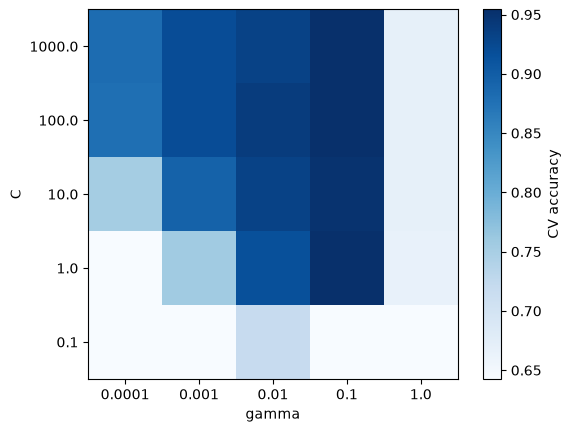

In [8]:
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

param_grid = {'svc__C': [0.1, 1, 10, 100, 1000],
              'svc__gamma': [0.0001, 0.001, 0.01, 0.1, 1]}
# selecao do modelo
grid = GridSearchCV(rbf, param_grid, cv=cv, scoring='accuracy', return_train_score=True)
grid.fit(X_train, y_train)

res = pd.DataFrame(grid.cv_results_)
table = res.pivot(index='param_svc__C', columns='param_svc__gamma', values='mean_test_score')
print(table.round(3))
best_std = res.loc[grid.best_index_, 'std_test_score']
print(f"best: {grid.best_params_} · accuracy {grid.best_score_:.3f} ± {best_std:.3f}")
ties = res[res['mean_test_score'] >= grid.best_score_ - best_std]
print(f"{len(ties)} of {len(res)} pairs are within one std of the best")
corner = (res['param_svc__C'] == 1) & (res['param_svc__gamma'] == 1)
print(f"training-fold accuracy · best pair {res.loc[grid.best_index_, 'mean_train_score']:.3f} · "
      f"C = 1, gamma = 1: {res.loc[corner, 'mean_train_score'].item():.3f}")

plt.imshow(table, cmap='Blues', origin='lower')
plt.xticks(range(5), table.columns); plt.yticks(range(5), table.index)
plt.xlabel('gamma'); plt.ylabel('C'); plt.colorbar(label='CV accuracy')
plt.show()

**Resposta.** Sim, o melhor $C$ depende do $\gamma$: com $\gamma = 0{,}0001$ só $C = 1000$ chega a 0,882, enquanto com $\gamma = 0{,}1$ qualquer $C \ge 1$ já dá cerca de 0,95. O pior canto é o de $\gamma$ grande: com $\gamma = 1$ a CV fica em 0,665–0,669 para todo $C$ (e o treino em 1,000), enquanto o $\gamma$ pequeno só é ruim com $C$ pequeno. O vencedor é $C = 1$, $\gamma = 0{,}1$ com 0,954 ± 0,019, e 5 dos 25 pares estão a menos de um desvio dele.

**Simulação: o que o γ faz, visto de dentro.** Fixe `C = 1` e varra o $\gamma$ de 0,001 a 1. Para cada valor, conte os vetores de suporte e compare a acurácia de treino com a de validação cruzada. O vão entre as duas conta a história do sobreajuste melhor que qualquer um dos números sozinho.

In [9]:
rows = []
for gamma in [0.001, 0.01, 0.1, 1]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=gamma)).fit(X_train, y_train)
    a = np.abs(pipe[-1].dual_coef_[0])
    train_acc = pipe.score(X_train, y_train)
    cv_acc = cross_val_score(pipe, X_train, y_train, cv=cv).mean()
    rows.append({'gamma': gamma, 'support vectors': len(a), 'alpha = C': (a >= 1 - 1e-6).sum(),
                 'train': train_acc, 'CV': cv_acc, 'gap': train_acc - cv_acc})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 gamma  support vectors  alpha = C  train    CV   gap
 0.001              184        178  0.802 0.757 0.046
 0.010              109         83  0.943 0.916 0.027
 0.100              148         29  0.989 0.954 0.034
 1.000              231         87  1.000 0.665 0.335


**Leitura.** O número de vetores de suporte faz um U: 184, 109, 148 e 231. Com $\gamma = 0{,}001$ o modelo subajusta (treino 0,802, CV 0,757) e 178 dos 184 vetores têm $\alpha = C$, ou seja, são violações da margem. Em $\gamma = 0{,}1$ a CV chega a 0,954 com um vão de só 0,034; em $\gamma = 1$ o modelo decora o treino (1,000) e a CV despenca para 0,665, um vão de 0,335.

## Passo 7 — por dentro do vencedor: os vetores de suporte

**Preveja.** O vencedor tem $\gamma = 0{,}1$, razoavelmente local, em 34 dimensões. Você espera que ele guarde uns 10% das linhas de treino como vetores de suporte ou bem mais?

In [10]:
best = grid.best_estimator_                     # reajustado em todo o X_train
svc = best[-1]
print(f"support vectors (bad, good): {svc.n_support_} · {svc.n_support_.sum()} of {len(X_train)} rows")

alpha = np.abs(svc.dual_coef_[0])
print(f"on the margin (0 < alpha < C): {(alpha < svc.C - 1e-6).sum()} · "
      f"inside it or misclassified (alpha = C): {(alpha >= svc.C - 1e-6).sum()}")

m = np.where(y_train == 1, 1, -1) * best.decision_function(X_train)   # m = y · f(x)
print(f"training rows with m < 0 (misclassified): {(m < 0).sum()} · "
      f"training accuracy {best.score(X_train, y_train):.3f}")

support vectors (bad, good): [91 57] · 148 of 263 rows
on the margin (0 < alpha < C): 119 · inside it or misclassified (alpha = C): 29
training rows with m < 0 (misclassified): 3 · training accuracy 0.989


**Resposta.** Bem mais: o vencedor guarda 148 das 263 linhas (56%) como vetores de suporte, 91 "ruins" e 57 "bons". Só 29 têm $\alpha = C$ (dentro da margem ou erradas) e apenas 3 linhas de treino estão do lado errado, daí a acurácia de treino de 0,989.

**Simulação: escalonar num conjunto que já está normalizado.** O passo 1 notou que todos os atributos já estão entre −1 e 1. Então o `StandardScaler` ainda faz diferença aqui? Meça a acurácia de CV do vencedor com e sem ele e olhe antes a faixa de desvios-padrão das colunas.

In [11]:
stds = X_train.std()
print(f"values from {X_train.min().min():.0f} to {X_train.max().max():.0f} · "
      f"column std from {stds.min():.3f} to {stds.max():.3f}")
params = {'C': grid.best_params_['svc__C'], 'gamma': grid.best_params_['svc__gamma']}
for name, est in [('without scaler', SVC(kernel='rbf', **params)),
                  ('with scaler', make_pipeline(StandardScaler(), SVC(kernel='rbf', **params)))]:
    print(f"{name:15s} CV accuracy {cross_val_score(est, X_train, y_train, cv=cv).mean():.3f}")

values from -1 to 1 · column std from 0.000 to 0.655
without scaler  CV accuracy 0.943


with scaler     CV accuracy 0.954

**Leitura.** Os valores vão de −1 a 1, mas os desvios-padrão das colunas vão de 0,000 a 0,655, então as escalas ainda são bem diferentes. Sem o scaler a CV do vencedor fica em 0,943; com ele, 0,954: um ganho de 1,1 ponto, menor que o desvio entre folds (0,019), mas na direção esperada, porque o RBF soma diferenças de todas as colunas. Como o scaler custa pouco e a escala real nem sempre é conhecida, ele fica no pipeline.

## Passo 8 — a SVM é mesmo melhor? Rivais ajustados, mesmos folds

**Preveja.** Agora os rivais também são ajustados. A vantagem da SVM RBF vai sobreviver a isso? E por que o desvio das *diferenças* por fold deve ser menor que o desvio de cada modelo?

In [12]:
rivals = {
    'logistic regression': GridSearchCV(models['logistic regression'],
                                        {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
                                        cv=cv),
    'k-NN': GridSearchCV(models['k-NN (k = 5)'],
                         {'kneighborsclassifier__n_neighbors': [1, 3, 5, 7, 9, 15, 25]}, cv=cv),
}


def fold_scores(g):                              # os 5 escores por fold do vencedor de uma grade
    return [g.cv_results_[f'split{k}_test_score'][g.best_index_] for k in range(5)]


folds = pd.DataFrame({'RBF SVM': fold_scores(grid)})
for name, g in rivals.items():
    g.fit(X_train, y_train)
    print(f"{name}: {g.best_params_}")
    folds[name] = fold_scores(g)
folds['SVM - LR'] = folds['RBF SVM'] - folds['logistic regression']
folds['SVM - k-NN'] = folds['RBF SVM'] - folds['k-NN']
print(folds.round(3))
print(pd.DataFrame({'mean': folds.mean(), 'std': folds.std(ddof=0)}).T.round(3))

logistic regression: {'logisticregression__C': 10}


k-NN: {'kneighborsclassifier__n_neighbors': 1}
   RBF SVM  logistic regression   k-NN  SVM - LR  SVM - k-NN
0    0.925                0.868  0.830     0.057       0.094
1    0.962                0.887  0.849     0.075       0.113
2    0.962                0.887  0.887     0.075       0.075
3    0.942                0.904  0.846     0.038       0.096
4    0.981                0.923  0.885     0.058       0.096
      RBF SVM  logistic regression   k-NN  SVM - LR  SVM - k-NN
mean    0.954                0.894  0.859     0.061       0.095
std     0.019                0.019  0.022     0.014       0.012


**Resposta.** Sobrevive: a logística ajustada ($C = 10$) faz 0,894 e o k-NN ajustado ($k = 1$) 0,859, contra 0,954 da SVM RBF, que vence em todos os 5 folds (SVM − LR = 0,061 ± 0,014; SVM − k-NN = 0,095 ± 0,012). O desvio das diferenças é menor que o de cada modelo (0,014 contra 0,019) porque os modelos são avaliados nas mesmas linhas: um fold "difícil" derruba todos juntos, e essa parte do ruído se cancela na subtração.

## Passo 9 — o único teste

**Preveja.** A CV disse 0,954 ± 0,019. Com 88 linhas de teste, quanto um único erro vale? Um resultado alguns pontos abaixo da CV seria motivo para voltar e reajustar?

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pred = best.predict(X_test)
print(confusion_matrix(y_test, pred, labels=[1, 0]))
print(classification_report(y_test, pred, target_names=['bad', 'good'], digits=3))
print(f"test ROC AUC (from decision_function): {roc_auc_score(y_test, best.decision_function(X_test)):.3f}")

[[52  4]
 [ 4 28]]
              precision    recall  f1-score   support

         bad      0.875     0.875     0.875        32
        good      0.929     0.929     0.929        56

    accuracy                          0.909        88
   macro avg      0.902     0.902     0.902        88
weighted avg      0.909     0.909     0.909        88

test ROC AUC (from decision_function): 0.956


**Resposta.** Um erro vale 1,14 ponto. O teste deu 0,909 (8 erros: 4 de cada classe) e ROC AUC 0,956, uns 4,5 pontos abaixo da CV, ou seja, cerca de 4 linhas. Não é motivo para voltar e reajustar: o teste só vale como estimativa honesta se for usado uma vez, e reajustar olhando para ele o transformaria em mais um conjunto de validação.

**Para fechar a aula.** Em uma frase cada: (1) o que o truque do kernel evita calcular? (2) Por que $C$ e $\gamma$ precisam ser buscados juntos? (3) Quando uma SVM com kernel deixa de ser prática e o que usar no lugar?

**Resposta.**
1. O truque do kernel evita calcular explicitamente o mapeamento $\varphi(x)$ para o espaço de atributos (de dimensão infinita, no RBF): só os produtos internos $k(x, x')$ entre pares de linhas são necessários.
2. Porque eles interagem: o $\gamma$ define o quão local é a fronteira e o $C$ quanto ela tolera erros, e o melhor $C$ muda com o $\gamma$ (na grade, $C = 1000$ com $\gamma = 0{,}0001$ e $C = 1$ com $\gamma = 0{,}1$).
3. Quando o número de linhas passa de algumas dezenas de milhares, porque a matriz de kernel cresce com $n^2$ e o treino entre $n^2$ e $n^3$; aí se usa uma SVM linear (`LinearSVC`, `SGDClassifier`), uma aproximação do kernel (`Nystroem`) com um modelo linear, ou modelos de árvores.

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Kernel polinomial.** Troque o RBF por `SVC(kernel='poly', coef0=1)` e ajuste `degree` (2, 3, 4) e `C` com o mesmo `cv`. Ele chega a menos de um desvio-padrão do vencedor RBF? Quantos vetores de suporte ele guarda?
2. **CV aninhada.** Rode `cross_val_score(grid, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=7))`. Esse escore avalia o *procedimento de ajuste inteiro* em folds que o ajuste nunca viu. Compare com `grid.best_score_` e com a acurácia de teste do passo 9: de qual dos dois ele fica mais perto?
3. **Probabilidades.** Monte `CalibratedClassifierCV(grid.best_estimator_, method='sigmoid', ensemble=False, cv=cv)` e compare a ROC AUC dele em validação cruzada (a `cv_summary` funciona com ele) com a do próprio vencedor (`cv_summary(grid.best_estimator_)`). Por que as duas ficam tão próximas? Depois use `cross_val_predict` nos dois para contar as linhas de treino cuja classe prevista muda.
4. **Multiclasse.** No `load_digits`, ajuste `C` e `gamma` da `SVC` com um `GridSearchCV` e um `cv` estratificado de 5 folds. Quantos classificadores de pares o vencedor treina e quantos vetores de suporte ele guarda para o dígito 8 comparado ao dígito 0? Quais dígitos são os mais difíceis, segundo a matriz de confusão das previsões fora do fold?

### Sua vez (fundamental) — exercício 1: a margem à mão

**Conta à mão.** Por simetria, $w = (a, a)$. Os negativos mais próximos continuam sendo B e C (na reta $x_1 + x_2 = 1$) e agora D, E e F estão todos na reta $x_1 + x_2 = 5$. Impondo $f(B) = a + b = -1$ e $f(D) = 5a + b = +1$: $a = \tfrac{1}{2}$ e $b = -\tfrac{3}{2}$. Então $\lVert w \rVert = \tfrac{\sqrt{2}}{2} \approx 0{,}707$ e a rua mede $2/\lVert w \rVert = 2\sqrt{2} \approx 2{,}828$, a distância entre as duas retas.

In [14]:
points = np.array([[0, 0], [1, 0], [0, 1], [2.5, 2.5], [3, 2], [2, 3]])   # A, B, C, D (movido), E, F
labels = np.array([-1, -1, -1, 1, 1, 1])
toy = SVC(kernel='linear', C=1e6, tol=1e-8).fit(points, labels)
w, b = toy.coef_[0], toy.intercept_[0]
print(f"w = {w.round(3)} · b = {b:.3f} · ||w|| = {np.linalg.norm(w):.3f} · street = {2 / np.linalg.norm(w):.3f}")
print("support vectors:", [('ABCDEF')[i] for i in toy.support_])
print("margins m = y·f(x):", (labels * toy.decision_function(points)).round(3))

w = [0.5 0.5] · b = -1.500 · ||w|| = 0.707 · street = 2.828
support vectors: ['C', 'F']
margins m = y·f(x): [1.5 1.  1.  1.  1.  1. ]


**Conclusão.** A biblioteca confirma a conta: $w = (0{,}5;\ 0{,}5)$, $b = -1{,}5$, $\lVert w \rVert = 0{,}707$ e rua de 2,828, mais larga que os 2,121 da seção 2, porque D se afastou dos negativos. B, C, D, E e F ficam todos sobre a margem ($m = 1$, só A tem 1,5); o `SVC` lista só C e F como vetores de suporte porque, com tantos pontos empatados na margem, a solução dual não é única e o solver escolhe um conjunto mínimo de $\alpha$ não nulos.

### Sua vez (fundamental) — exercício 2: hinge contra log loss

curves cross at m ≈ 0.54 (loss 0.459)
m = -3: hinge 4.000 · log loss 3.049
m = +0: hinge 1.000 · log loss 0.693
m = +1: hinge 0.000 · log loss 0.313
m = +2: hinge 0.000 · log loss 0.127
m = +3: hinge 0.000 · log loss 0.049


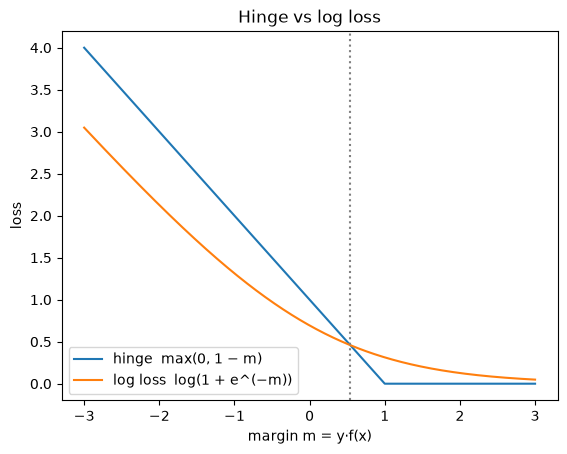

In [15]:
import matplotlib.pyplot as plt

mg = np.linspace(-3, 3, 601)
hinge = np.maximum(0, 1 - mg)
logloss = np.log1p(np.exp(-mg))
cross = mg[np.argmin(np.abs(hinge - logloss)[mg < 1])]
print(f"curves cross at m ≈ {cross:.2f} (loss {np.log1p(np.exp(-cross)):.3f})")
for m_ in [-3, 0, 1, 2, 3]:
    print(f"m = {m_:+d}: hinge {max(0, 1 - m_):.3f} · log loss {np.log1p(np.exp(-m_)):.3f}")

plt.plot(mg, hinge, label='hinge  max(0, 1 − m)')
plt.plot(mg, logloss, label='log loss  log(1 + e^(−m))')
plt.axvline(cross, color='gray', ls=':')
plt.xlabel('margin m = y·f(x)'); plt.ylabel('loss'); plt.title('Hinge vs log loss')
plt.legend(); plt.show()

**Conclusão.** As curvas se cruzam em $m \approx 0{,}54$ (perda 0,459). Num erro grosseiro ($m = -3$) a hinge pune mais (4,000 contra 3,049): as duas crescem linearmente, mas a hinge fica cerca de uma unidade acima. Já a log loss continua "escutando" pontos bem classificados (0,127 em $m = 2$, 0,049 em $m = 3$), enquanto a hinge zera a partir de $m = 1$, e é por isso que só os vetores de suporte importam na SVM.

### Sua vez (fundamental) — exercício 3: quantos vetores de suporte no breast cancer?

In [16]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(       # o teste fica trancado, não é usado
    bc.data, bc.target, test_size=0.25, stratify=bc.target, random_state=42)
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C)).fit(Xb_train, yb_train)
    rows.append({'C': C,
                 'street 2/||w||': 2 / np.linalg.norm(pipe[-1].coef_),
                 'support vectors': pipe[-1].n_support_.sum(),
                 'train': pipe.score(Xb_train, yb_train),
                 'CV': cross_val_score(pipe, Xb_train, yb_train, cv=cv).mean()})
print(f"{len(Xb_train)} training rows")
print(pd.DataFrame(rows).round(3).to_string(index=False))

426 training rows
     C  street 2/||w||  support vectors  train    CV
  0.01           2.923               97  0.981 0.974
  0.10           1.488               47  0.984 0.977
  1.00           0.675               34  0.991 0.972
 10.00           0.260               26  0.995 0.965
100.00           0.080               26  1.000 0.967


**Conclusão.** A relação entre $C$ e vetores de suporte é a mesma: ao subir o $C$ de 0,01 para 100, os vetores caem de 97 para 26 e a rua encolhe de 2,923 para 0,080, enquanto o treino sobe até 1,000. A curva da CV tem um arco, mas bem mais achatado: 0,974, 0,977 (máximo em $C = 0{,}1$), 0,972, 0,965 e 0,967, uma variação de 1,2 ponto, dentro do ruído. O breast cancer é quase linearmente separável, então o $C$ importa bem menos que no Ionosphere.

### Sua vez (avançado) — exercício 1: kernel polinomial

In [17]:
poly = make_pipeline(StandardScaler(), SVC(kernel='poly', coef0=1))
grid_poly = GridSearchCV(poly, {'svc__degree': [2, 3, 4], 'svc__C': [0.01, 0.1, 1, 10, 100]}, cv=cv)
grid_poly.fit(X_train, y_train)

res_poly = pd.DataFrame(grid_poly.cv_results_)
print(res_poly.pivot(index='param_svc__C', columns='param_svc__degree', values='mean_test_score').round(3))
poly_std = res_poly.loc[grid_poly.best_index_, 'std_test_score']
print(f"best poly: {grid_poly.best_params_} · accuracy {grid_poly.best_score_:.3f} ± {poly_std:.3f}")
print(f"RBF winner: accuracy {grid.best_score_:.3f} ± {best_std:.3f} · "
      f"gap {grid.best_score_ - grid_poly.best_score_:.3f}")
n_sv_poly = grid_poly.best_estimator_[-1].n_support_.sum()
print(f"support vectors · poly {n_sv_poly} · RBF {svc.n_support_.sum()} (of {len(X_train)} rows)")

param_svc__degree      2      3      4
param_svc__C                          
0.01               0.643  0.715  0.738
0.10               0.859  0.882  0.882
1.00               0.901  0.913  0.897
10.00              0.901  0.894  0.875
100.00             0.897  0.878  0.875
best poly: {'svc__C': 1, 'svc__degree': 3} · accuracy 0.913 ± 0.019
RBF winner: accuracy 0.954 ± 0.019 · gap 0.042
support vectors · poly 77 · RBF 148 (of 263 rows)


**Conclusão.** O melhor polinomial ($\text{degree} = 3$, $C = 1$) faz 0,913 ± 0,019, 0,042 abaixo do RBF (0,954 ± 0,019): a distância é mais de dois desvios, então ele não chega a um desvio-padrão do vencedor. Ele guarda 77 vetores de suporte, cerca de metade dos 148 do RBF.

### Sua vez (avançado) — exercício 2: CV aninhada

In [18]:
from sklearn.metrics import accuracy_score

nested = cross_val_score(grid, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=7))
print(f"nested CV: {nested.mean():.3f} ± {nested.std():.3f} · folds {nested.round(3)}")
print(f"grid.best_score_: {grid.best_score_:.3f}")
print(f"test accuracy (step 9, not recomputed on new data): {accuracy_score(y_test, pred):.3f}")

nested CV: 0.954 ± 0.016 · folds [0.962 0.962 0.962 0.923 0.962]
grid.best_score_: 0.954
test accuracy (step 9, not recomputed on new data): 0.909


**Conclusão.** A CV aninhada dá 0,954 ± 0,016, praticamente igual ao `grid.best_score_` (0,954) e bem acima do teste (0,909). Com 25 pares e um platô largo de bons valores, o otimismo da busca aqui é desprezível; a queda no teste vem da variância de só 88 linhas (4 erros a mais), não do vencedor ter sido escolhido nos mesmos folds.

### Sua vez (avançado) — exercício 3: probabilidades

In [19]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_predict

calibrated = CalibratedClassifierCV(grid.best_estimator_, method='sigmoid', ensemble=False, cv=cv)
print(f"calibrated: {cv_summary(calibrated)}")
print(f"RBF winner: {cv_summary(grid.best_estimator_)}")

pred_svm = cross_val_predict(grid.best_estimator_, X_train, y_train, cv=cv)
pred_cal = cross_val_predict(calibrated, X_train, y_train, cv=cv)
print(f"training rows whose predicted class changes: {(pred_svm != pred_cal).sum()} of {len(X_train)}")

calibrated: {'accuracy': '0.951 ± 0.019', 'roc_auc': '0.990 ± 0.007'}
RBF winner: {'accuracy': '0.954 ± 0.019', 'roc_auc': '0.990 ± 0.007'}


training rows whose predicted class changes: 1 of 263


**Conclusão.** A ROC AUC é a mesma, 0,990 ± 0,007 nos dois. Com `ensemble=False`, a SVM é reajustada em todo o fold de treino e a sigmoide é uma função monótona do `decision_function`, então a ordem das linhas não muda e a AUC também não. O que muda é o limiar (probabilidade 0,5 em vez de $f(x) = 0$): a acurácia vai de 0,954 para 0,951, e só 1 das 263 linhas troca de classe prevista.

### Sua vez (avançado) — exercício 4: multiclasse no `load_digits`

In [20]:
from sklearn.datasets import load_digits

digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(       # o teste fica trancado, não é usado
    digits.data, digits.target, test_size=0.25, stratify=digits.target, random_state=42)
cv_d = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_d = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                      {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.0001, 0.001, 0.01, 0.1]}, cv=cv_d)
grid_d.fit(Xd_train, yd_train)
svc_d = grid_d.best_estimator_[-1]
print(f"best: {grid_d.best_params_} · CV accuracy {grid_d.best_score_:.3f}")
print(f"pairwise classifiers (one-vs-one): {len(svc_d.classes_) * (len(svc_d.classes_) - 1) // 2} · "
      f"dual_coef_ shape {svc_d.dual_coef_.shape}")
print("support vectors per digit:", dict(zip(svc_d.classes_.tolist(), svc_d.n_support_.tolist())))
print(f"digit 8: {svc_d.n_support_[8]} · digit 0: {svc_d.n_support_[0]} · total {svc_d.n_support_.sum()} of {len(Xd_train)}")

oof_d = cross_val_predict(grid_d.best_estimator_, Xd_train, yd_train, cv=cv_d)
cm_d = confusion_matrix(yd_train, oof_d)
print(cm_d)
errors = pd.Series(cm_d.sum(axis=1) - np.diag(cm_d), index=svc_d.classes_)
print("out-of-fold errors per true digit:", errors.to_dict())

best: {'svc__C': 10, 'svc__gamma': 0.01} · CV accuracy 0.984
pairwise classifiers (one-vs-one): 45 · dual_coef_ shape (9, 619)
support vectors per digit: {0: 34, 1: 73, 2: 61, 3: 61, 4: 65, 5: 63, 6: 46, 7: 69, 8: 77, 9: 70}
digit 8: 77 · digit 0: 34 · total 619 of 1347


[[133   0   0   0   0   0   0   0   0   0]
 [  0 136   0   0   0   0   0   0   0   0]
 [  0   0 130   0   2   0   0   0   1   0]
 [  0   0   1 133   1   1   0   0   1   0]
 [  0   0   0   0 136   0   0   0   0   0]
 [  0   0   0   0   1 132   1   0   0   2]
 [  0   0   0   0   0   0 136   0   0   0]
 [  0   0   0   0   0   0   0 133   0   1]
 [  0   1   1   1   0   0   0   0 127   1]
 [  0   0   0   0   0   2   0   1   2 130]]
out-of-fold errors per true digit: {0: 0, 1: 0, 2: 3, 3: 4, 4: 0, 5: 4, 6: 0, 7: 1, 8: 4, 9: 5}


**Conclusão.** O vencedor ($C = 10$, $\gamma = 0{,}01$, CV 0,984) treina 10 · 9 / 2 = 45 classificadores de pares (um contra um) e guarda 619 vetores de suporte nas 1347 linhas de treino: 77 do dígito 8 contra 34 do dígito 0, o mais e o menos "difíceis" de separar. Pela matriz fora do fold, os dígitos mais difíceis são o 9 (5 erros, confundido com 5 e 8), seguido de 3, 5 e 8 (4 erros cada); 0, 1, 4 e 6 não têm erro.